# 00-data-neu — Dữ liệu NEU-DET: giao thức, ảnh, nhãn

**Câu hỏi**: mô hình thấy những ảnh NEU nào, ở phiên nào; NEU khác GC10 ở đâu (mất cân bằng, cỡ lỗi, nhãn, lỗi đi chung)? (Q00.01, Q00.02)

### Nguồn gốc (provenance)

In commit và trạng thái dirty của code, rồi đặt `XLA_FLAGS` trước mọi lần import jax (mẫu ở `lab/README.vi.md` §11).

In [1]:
# cell 0: provenance (run first)
import os, subprocess, sys
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "main.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path[:0] = [str(ROOT), str(ROOT / "lab")]
import replay; os.environ["XLA_FLAGS"] = replay._xla_flags()   # GPU deterministic mode before any jax import
git = lambda *a: subprocess.run(["git", *a], capture_output=True, text=True).stdout.strip()
print("commit", git("rev-parse", "--short", "HEAD"),
      "| code dirty", bool(git("status", "--porcelain", "--", ".", ":(exclude)runs", ":(exclude)notes",
                               ":(exclude)lab/*.ipynb", ":(exclude)lab/*.md")),
      "| XLA_FLAGS", os.environ["XLA_FLAGS"])

commit bba8722 | code dirty False | XLA_FLAGS --xla_gpu_deterministic_ops=true


   - **Kết quả**: commit `bba8722`, code dirty False, XLA_FLAGS `--xla_gpu_deterministic_ops=true`.

## 1. Giao thức

### 1.1 Bảng ảnh của file split

Mỗi ảnh một dòng, xếp theo thứ tự hàng (row order) của file đặc trưng (`lab/data_io.py`), rồi đếm ảnh theo vai trò (role). Ranh giới 192 ảnh mỗi lớp được ghi ở hai nơi: `labeled_frac` trong file split, vì phase 1 chỉ fine-tune trên phần này của lớp cơ sở; và hằng số trong `dataloaders/neudet.py` (phase 2). Cell dừng nếu hai nơi cho số khác nhau.

In [2]:
# cell 1: the image table of the split file (lab/data_io.py)
import hashlib, json
import numpy as np, pandas as pd
import data_io
SPLIT = Path(data_io.SPLITS["neudet"])
split = json.loads(SPLIT.read_text())
df = data_io.images("neudet")
ROLES = ["S0", "reserve", "S1", "unused", "test"]
n_frac = {c: int(split["labeled_frac"] * len(split["train"][c])) for c in split["classes"]}   # phase 1: dino-neudet.py
print("split", SPLIT, "| sha256", hashlib.sha256(SPLIT.read_bytes()).hexdigest()[:8], "| images", len(df))
print("classes", split["classes"], "| base", data_io.NEU["n_base"])
print("labeled per class: labeled_frac x train", sorted(set(n_frac.values())), "| loader n_use", data_io.NEU["n_use"])
assert set(n_frac.values()) == {data_io.NEU["n_use"]}, "phase 1 and the loader disagree on the labeled part"
print("roles", df["role"].value_counts().reindex(ROLES).to_dict())
df.head(3)

split splits/neu_split.json | sha256 49c23576 | images 1800
classes ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches'] | base 3
labeled per class: labeled_frac x train [192] | loader n_use 192
roles {'S0': 576, 'reserve': 144, 'S1': 576, 'unused': 144, 'test': 360}


,path,cls,name,part,rank,row,role
0,datasets/NEU-DET/train/images/crazing/crazing_...,0,crazing,train,0,0,S0
1,datasets/NEU-DET/train/images/crazing/crazing_...,0,crazing,train,1,1,S0
2,datasets/NEU-DET/train/images/crazing/crazing_...,0,crazing,train,2,2,S0


- **Kết quả**: 1800 ảnh, file split sha256 `49c23576`: S0 576, reserve 144, S1 576, unused 144, test 360. Ranh giới mỗi lớp: `labeled_frac` × 240 = 192, trùng `n_use` 192 của loader.
- **Ý nghĩa**: phase 1 chỉ fine-tune trên 192 ảnh đầu của mỗi lớp cơ sở (`feature_extractor/dino-neudet.py`), tức đúng 576 ảnh S0 của phase 2, nên ảnh reserve và ảnh lớp mới không lọt vào bước fine-tune. Pool của phiên S1 = S1 (576) + 3 × 12 ảnh bốc từ reserve = 612.

### 1.2 Dựng lại file split từ dữ liệu gốc

Chạy lại `scripts/make_neu_split.py` trên thư mục ảnh, ghi ra file tạm, rồi so từng byte với file split của repo. Không ghi đè file trong repo, vì các run trích đặc trưng NEU đã băm file này (`f98070636f531cce`). Thứ tự ảnh train của mỗi lớp là một hoán vị ngẫu nhiên (random permutation) sinh từ `np.random.default_rng(0)`. NumPy không cam kết giữ nguyên dãy số của `Generator` giữa các phiên bản (NEP 19), nên cell in kèm phiên bản numpy.

In [3]:
# cell 2: rebuild the split file from the raw data into a temporary file; the repo file is never written
import contextlib, importlib.util, io, tempfile
spec = importlib.util.spec_from_file_location("make_neu_split", "scripts/make_neu_split.py")
mk = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mk)
mk.OUT = str(Path(tempfile.mkdtemp()) / "neu_split.json")
with contextlib.redirect_stdout(io.StringIO()) as log:
    mk.main()
same = Path(mk.OUT).read_bytes() == SPLIT.read_bytes()
print(*log.getvalue().splitlines()[:2], sep="\n")
print("numpy", np.__version__, "| same bytes as", SPLIT, ":", same)
assert same, "the raw data do not give the split file"

classes (id order): ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
per class: train 240 = 192 labeled/session + 48 pool; test 60
numpy 2.5.3 | same bytes as splits/neu_split.json : True


- **Kết quả**: dựng lại từ thư mục ảnh cho file trùng từng byte với `splits/neu_split.json` (numpy 2.5.3). Mỗi lớp: train 240 = 192 có nhãn hoặc dữ liệu phiên + 48 pool; test 60.
- **Ý nghĩa**: file split tái lập được từ dữ liệu gốc, và hoán vị của `default_rng(0)` không đổi ở numpy 2.5.3. Các run trích đặc trưng NEU dựng từ đúng giao thức này.

### 1.3 Số ảnh theo lớp và vai trò, mức lệch lớp

Bảng chéo lớp × vai trò, rồi tính mức lệch lớp (class imbalance) của từng vai trò: số ảnh của lớp đông nhất chia cho lớp ít nhất, chỉ tính các lớp có ảnh ở vai trò đó. Để so với GC10 ở `00-data-gc10` §1.3, nơi S1 có silk_spot 420 ảnh và rolled_pit 17 ảnh.

In [4]:
# cell 3: images per class and role, class imbalance per role
tab = pd.crosstab(df["name"], df["role"]).reindex(index=split["classes"], columns=ROLES, fill_value=0)
print(tab.to_string())
used = {r: tab[r][tab[r] > 0] for r in ROLES}
print("imbalance max/min by role:", {r: round(float(v.max() / v.min()), 2) for r, v in used.items()})

role              S0  reserve   S1  unused  test
name                                            
crazing          192       48    0       0    60
inclusion        192       48    0       0    60
patches          192       48    0       0    60
pitted_surface     0        0  192      48    60
rolled-in_scale    0        0  192      48    60
scratches          0        0  192      48    60
imbalance max/min by role: {'S0': 1.0, 'reserve': 1.0, 'S1': 1.0, 'unused': 1.0, 'test': 1.0}


- **Kết quả**: mỗi lớp cơ sở có S0 192, reserve 48, test 60; mỗi lớp mới có S1 192, unused 48, test 60. Mức lệch lớp ở mọi vai trò là 1.0.
- **Ý nghĩa**: NEU cân bằng tuyệt đối, khác GC10 (S1 có silk_spot 420 ảnh, rolled_pit 17 ảnh; `00-data-gc10` §1.3). Vì vậy độ khó của GC10 không thể do NEU giải thích qua mất cân bằng: NEU không có yếu tố này để so. Muốn tách riêng tác động của mất cân bằng thì phải dựng lại pool S1 của NEU theo tỉ lệ của GC10 (Q00.02).

### 1.4 Ảnh trùng điểm ảnh giữa train và test

Băm (hash) điểm ảnh đã giải mã của 1800 ảnh, rồi tìm các nhóm ảnh có điểm ảnh giống hệt nhau, nhất là nhóm có ảnh ở cả train lẫn test. Ảnh như vậy là rò rỉ (leakage): mô hình đã thấy ảnh test lúc train. Cách này chỉ bắt được ảnh trùng chính xác; ảnh gần giống nhau (nén lại, cắt lệch) thì không bắt được.

In [5]:
# cell 4: pixel-identical images, within and across train and test (md5 of decoded pixels)
from PIL import Image
df["pix"] = [hashlib.md5(np.asarray(Image.open(p)).tobytes()).hexdigest() for p in df["path"]]
dup = df[df["pix"].map(df.groupby("pix").size()) > 1]
cross = dup.groupby("pix")["part"].nunique().gt(1)
print("images", len(df), "| distinct pixel contents", df["pix"].nunique(),
      "| duplicate groups", dup["pix"].nunique(), "| groups across train and test", int(cross.sum()))
print(dup.sort_values("pix")[["name", "path", "role"]].head(20).to_string(index=False) if len(dup) else "no duplicates")

images 1800 | distinct pixel contents 1799 | duplicate groups 1 | groups across train and test 0
   name                                                  path role
patches datasets/NEU-DET/train/images/patches/patches_101.jpg   S0
patches datasets/NEU-DET/train/images/patches/patches_105.jpg   S0


- **Kết quả**: 1800 ảnh, 1799 nội dung điểm ảnh khác nhau. Có đúng 1 nhóm trùng: `patches_101.jpg` và `patches_105.jpg`, cả hai đều thuộc S0. Không nhóm nào nằm ở cả train lẫn test.
- **Ý nghĩa**: không có rò rỉ train → test ở mức trùng chính xác. Cặp trùng nằm trong cùng lớp và cùng vai trò, nên S0 của patches thực chất có 191 ảnh khác nhau; ảnh hưởng không đáng kể. [SUY LUẬN] Nhiều khả năng đây là ảnh trùng có sẵn trong bộ NEU-DET gốc.

### 1.5 Thứ tự hàng của file đặc trưng

Hàng i của file đặc trưng là ảnh có `row` = i, nếu hai điều cùng đúng: các run trích đặc trưng đọc đúng file split này, và `build()` chưa đổi từ đó. Cách kiểm: so mã băm `exp.py` của file split với mã ghi trong `config.json` của 4 run (fz, ft r0, r1, r2), rồi xem `feature_extractor/dino-neudet.py` có đổi từ commit của các run đó không.

In [6]:
# cell 5: row i of a feature file is image i of the table: the extraction runs read this split file, build() unchanged
import importlib.util
spec = importlib.util.spec_from_file_location("exp", "scripts/exp.py")
exp = importlib.util.module_from_spec(spec)
spec.loader.exec_module(exp)
h = exp.hash_path(SPLIT)                                      # the hash exp.py writes in config.json
ext = {}
for d in sorted(Path("runs").glob("*__neu_f[tz]_cls3first_img80pct*")):
    if "_km_" not in d.name:                                  # phase-1 runs only
        c = json.loads((d / "config.json").read_text())
        ext[d.name] = (c["inputs"].get(str(SPLIT)), c["git"]["commit"][:7])
known = git("cat-file", "-t", "97c57ee") == "commit"         # else git diff prints nothing and looks unchanged
diff = git("diff", "--stat", "97c57ee", "HEAD", "--", "feature_extractor/dino-neudet.py")
print("hash_path of the split file:", h)
for k, v in ext.items():
    print(f"  {k}: split hash {v[0]}, commit {v[1]}")
print("commit 97c57ee in history:", known, "| dino-neudet.py changed since 97c57ee:", bool(diff))
assert len(ext) == 4 and all(v == (h, "97c57ee") for v in ext.values()) and known and not diff

hash_path of the split file: f98070636f531cce
  20261005_014929__neu_fz_cls3first_img80pct: split hash f98070636f531cce, commit 97c57ee
  20261005_014947__neu_ft_cls3first_img80pct_r0: split hash f98070636f531cce, commit 97c57ee
  20261005_015351__neu_ft_cls3first_img80pct_r1: split hash f98070636f531cce, commit 97c57ee
  20261005_015755__neu_ft_cls3first_img80pct_r2: split hash f98070636f531cce, commit 97c57ee
commit 97c57ee in history: True | dino-neudet.py changed since 97c57ee: False


- **Kết quả**: mã băm `exp.py` của file split là `f98070636f531cce`. Cả 4 run trích đặc trưng (fz, ft r0, r1, r2) ghi đúng mã này và đều chạy ở commit `97c57ee`. `dino-neudet.py` không đổi từ commit đó.
- **Ý nghĩa**: `build()` duyệt file split theo đúng thứ tự (DataLoader `shuffle=False`), nên hàng i của file đặc trưng là ảnh có `row` = i trong bảng. Đặc trưng NEU nối được với bảng ảnh của notebook này.

## 2. Ảnh

### 2.1 Kích thước và kênh màu

Đọc header của 1800 ảnh để lấy kích thước và chế độ màu (mode). Rồi so với kích thước ghi trong XML, vì tọa độ hộp lỗi ở mục 3 tính theo kích thước trong XML. Ảnh nào hai nơi lệch nhau thì hộp của ảnh đó không dùng thẳng được.

In [7]:
# cell 6: image size and mode from the file header, against the size written in the XML
from PIL import Image
rows = []
for p in df["path"]:
    with Image.open(p) as im:
        w, h, mode = *im.size, im.mode
    objs = data_io.objects("neudet", p)
    rows.append((w, h, mode) + ((objs[0]["W"], objs[0]["H"]) if objs else (np.nan, np.nan)))
df[["w", "h", "mode", "W", "H"]] = pd.DataFrame(rows, index=df.index)
print("header size and mode:", df.groupby(["w", "h", "mode"]).size().to_dict())
print("XML size:", df.groupby(["W", "H"], dropna=False).size().to_dict())
bad = df[(df["w"] != df["W"]) | (df["h"] != df["H"])]
print("header and XML disagree:", len(bad))
print(bad[["path", "w", "h", "W", "H"]].head(10).to_string(index=False) if len(bad) else "")

header size and mode: {(200, 200, 'RGB'): 1800}
XML size: {(200.0, 200.0): 1800}
header and XML disagree: 0



- **Kết quả**: cả 1800 ảnh đều 200×200, lưu ở chế độ RGB. Kích thước ghi trong XML đều là 200×200; không ảnh nào lệch giữa header và XML.
- **Ý nghĩa**: tọa độ hộp lỗi trong XML dùng thẳng được trên ảnh, không cần đổi tỉ lệ. Ảnh được lưu ba kênh, trái với ghi chú "một kênh" ở bàn giao; cell 2.2 kiểm xem ba kênh có giống hệt nhau không.

### 2.2 Kênh màu và độ sáng theo lớp

Hai việc trên cùng một lần đọc ảnh.
1. Ba kênh R, G, B có giống hệt nhau không, tức là ảnh xám (grayscale) lưu dưới dạng RGB.
2. Độ sáng (brightness) và độ tương phản (contrast) theo lớp. Độ sáng của một ảnh là giá trị trung bình của điểm ảnh, độ tương phản là độ lệch chuẩn của điểm ảnh. Mỗi lớp in trung vị và khoảng tứ phân vị [Q1, Q3].

NEU không có camera, nên khác biệt độ sáng giữa các lớp (nếu có) đến từ chính loại lỗi hoặc cách chụp từng lớp. Đặc trưng có thể học theo độ sáng thay vì theo hình dạng lỗi (shortcut learning).

In [8]:
# cell 7: are the three channels equal (grey stored as RGB)? brightness and contrast per class
stats = []
for p in df["path"]:
    a = np.asarray(Image.open(p).convert("RGB"), dtype=np.int16)
    stats.append((int(np.abs(a - a[..., :1]).max()), a[..., 0].mean(), a[..., 0].std()))
df[["chan_diff", "bright", "contrast"]] = pd.DataFrame(stats, index=df.index)
print("images whose 3 channels differ:", int((df["chan_diff"] > 0).sum()), "| max difference:", int(df["chan_diff"].max()))
q = lambda s: f"{s.median():.1f} [{s.quantile(.25):.1f}, {s.quantile(.75):.1f}]"
print(df.groupby("name").agg(bright=("bright", q), contrast=("contrast", q)).reindex(split["classes"]).to_string())

images whose 3 channels differ: 0 | max difference: 0
                               bright           contrast
name                                                    
crazing          149.0 [119.1, 164.9]  28.5 [25.8, 31.3]
inclusion          99.4 [84.9, 116.4]  11.2 [10.1, 13.9]
patches          139.1 [106.0, 162.5]  57.1 [47.3, 62.9]
pitted_surface   186.4 [148.1, 217.8]  26.4 [21.2, 32.0]
rolled-in_scale   125.9 [93.3, 136.7]  16.0 [13.7, 18.2]
scratches          92.5 [73.3, 116.4]  20.3 [15.7, 26.5]


- **Kết quả**: không ảnh nào có ba kênh khác nhau (chênh lớn nhất là 0). Độ sáng, trung vị [Q1, Q3]: pitted_surface 186.4 [148.1, 217.8] sáng nhất; scratches 92.5 [73.3, 116.4] và inclusion 99.4 [84.9, 116.4] tối nhất. Độ tương phản: patches 57.1 [47.3, 62.9] cao nhất, inclusion 11.2 [10.1, 13.9] thấp nhất. Khoảng [Q1, Q3] về độ tương phản của patches không chồng lên khoảng của lớp nào khác; khoảng của inclusion chỉ chồng lên rolled-in_scale.
- **Ý nghĩa**: NEU thực chất là ảnh xám lưu dạng RGB, nên ba kênh đầu vào của ViT mang cùng một thông tin. [SUY LUẬN] Chỉ hai con số toàn ảnh (độ sáng và độ tương phản) đã tách được một phần các lớp, nhất là patches và inclusion. Đó có thể là một lý do khiến NEU dễ và chạm trần, và đặc trưng có thể dựa vào thống kê toàn ảnh thay vì hình dạng lỗi.

### 2.3 Ảnh mẫu và khung crop 224

Phase 1 của NEU đổi cỡ ảnh lên 256 (Resize) rồi cắt giữa 224 (CenterCrop). Quy về ảnh gốc 200×200, phần được giữ là ô vuông giữa từ 12.5 đến 187.5 px ở mỗi trục; mỗi cạnh mất 12.5 px.

**Cách làm**: lề bị cắt mỗi cạnh = (256 − 224) / 2 × 200 / 256 = 12.5 px. Phần diện tích giữ lại = (175 / 200)² ≈ 76.6%.

Vẽ ảnh train đầu tiên của mỗi lớp, kèm hộp lỗi trong XML (vàng: đúng lớp của ảnh; đỏ: lớp khác) và khung crop (xanh, nét đứt), để thấy lỗi nằm sát mép thì bị cắt mất bao nhiêu. Mục 3.4 sẽ đo phần này trên toàn bộ ảnh.

kept window: [12.5, 187.5] on both axes = 76.6% of the image area


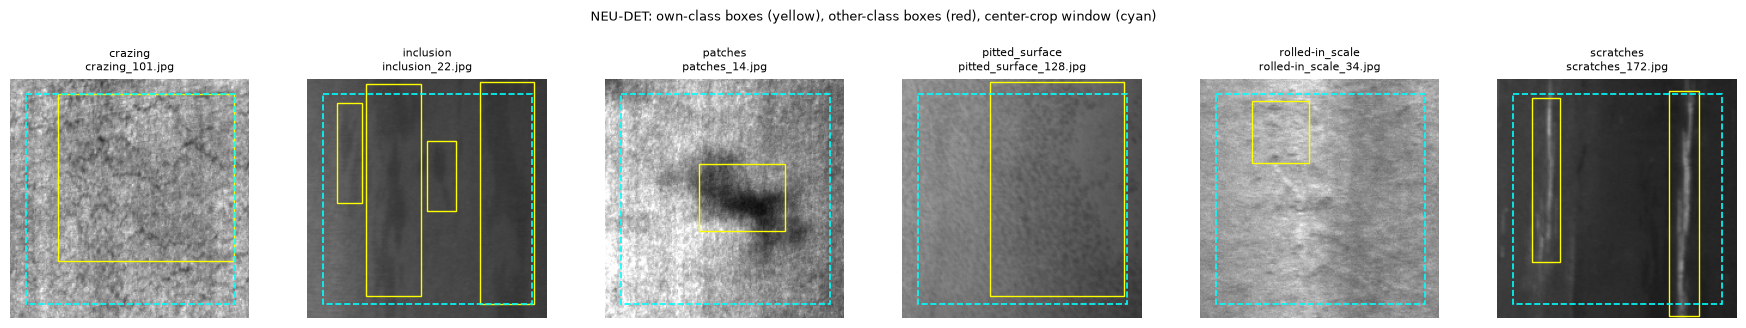

In [9]:
# cell 8: one train image per class, its XML boxes and the center-crop window of phase 1
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
RESIZE, CROP = 256, 224                                       # phase 1 of NEU: Resize(256) then CenterCrop(224)
m = (RESIZE - CROP) / 2 * 200 / RESIZE                        # margin cut on each side, in pixels of the 200x200 image
print(f"kept window: [{m}, {200 - m}] on both axes = {(200 - 2 * m) ** 2 / 200 ** 2:.1%} of the image area")
pick = df[(df["part"] == "train") & (df["rank"] == 0)]        # first train image of each class
fig, axs = plt.subplots(1, len(pick), figsize=(3 * len(pick), 3.3))
for ax, (_, r) in zip(axs, pick.iterrows()):
    ax.imshow(Image.open(r["path"]).convert("L"), cmap="gray", vmin=0, vmax=255)
    for o in data_io.objects("neudet", r["path"]) or []:
        ax.add_patch(Rectangle((o["xmin"], o["ymin"]), o["xmax"] - o["xmin"], o["ymax"] - o["ymin"],
                               fill=False, ec="yellow" if o["name"] == r["name"] else "red", lw=1))
    ax.add_patch(Rectangle((m, m), 200 - 2 * m, 200 - 2 * m, fill=False, ec="cyan", ls="--", lw=1.2))
    ax.set_title(f"{r['name']}\n{Path(r['path']).name}", fontsize=8); ax.axis("off")
fig.suptitle("NEU-DET: own-class boxes (yellow), other-class boxes (red), center-crop window (cyan)", fontsize=9)
plt.tight_layout(rect=(0, 0, 1, 0.92)); plt.show()

- **Kết quả**: khung giữ lại [12.5, 187.5] px ở mỗi trục, tức 76.6% diện tích ảnh. Trong 6 ảnh mẫu không có hộp lớp khác (đỏ). Hộp của crazing, patches và rolled-in_scale nằm trong khung. Một số hộp dài, gần hết chiều cao ảnh (một hộp của inclusion_22 và hai hộp của scratches), vượt khung ở mép trên hoặc mép dưới. Hộp của pitted_surface chiếm gần cả ảnh và chạm mép khung.
- **Ý nghĩa**: lỗi của NEU lớn so với ảnh, nhiều hộp phủ phần lớn ảnh. Crop chỉ cắt đầu mút của các lỗi dài (inclusion, scratches), không cắt mất cả lỗi. [SUY LUẬN] Vì vậy crop khó là lý do chính khiến lớp nào bị mất thông tin; mục 3.4 sẽ đo phần hộp bị cắt trên toàn bộ ảnh.

## 3. Nhãn

### 3.1 Cờ chất lượng nhãn theo lớp và vai trò

Dùng ba cờ kiểm nhãn của `data_io.diagnostics()`:
- `multi_defect`: XML có hơn một tên lỗi;
- `folder_not_in_xml`: XML không có lỗi nào thuộc lớp của thư mục ảnh;
- `no_xml`: ảnh không có file XML.

Đếm tổng số ảnh mang mỗi cờ, rồi tách số ảnh nhiều lỗi theo lớp × vai trò để so với GC10, nơi tỉ lệ ảnh nhiều lỗi là 35% ở S0 nhưng chỉ 4% ở S1.

In [10]:
# cell 9: label flags of data_io.diagnostics(), and multi-defect images by class and role
diag = data_io.diagnostics("neudet")
key = df["path"].map(lambda p: "/".join(Path(p).parts[-2:]))
for flag, keys in diag.items():
    df[flag] = key.isin(set(keys))
print("diagnostics:", {k: len(v) for k, v in diag.items()})
tab = df.groupby(["name", "role"])["multi_defect"].agg(["sum", "size"])
tab = (tab["sum"].astype(str) + "/" + tab["size"].astype(str)).unstack("role").reindex(index=split["classes"], columns=ROLES)
print("multi_defect images / images, by class and role:"); print(tab.fillna("-").to_string())

diagnostics: {'multi_defect': 123, 'folder_not_in_xml': 0, 'no_xml': 0}
multi_defect images / images, by class and role:
role                 S0 reserve      S1 unused   test
name                                                 
crazing           4/192    1/48       -      -   0/60
inclusion         0/192    0/48       -      -   0/60
patches          18/192    5/48       -      -   6/60
pitted_surface        -       -  22/192   3/48  14/60
rolled-in_scale       -       -   0/192   0/48   0/60
scratches             -       -  37/192  10/48   3/60


- **Kết quả**: 123 ảnh có nhiều loại lỗi; `folder_not_in_xml` 0; `no_xml` 0. Ảnh nhiều lỗi chỉ có ở 4 lớp:
  - patches: S0 18/192, reserve 5/48, test 6/60;
  - crazing: S0 4/192, reserve 1/48, test 0/60;
  - pitted_surface: S1 22/192, unused 3/48, test 14/60;
  - scratches: S1 37/192, unused 10/48, test 3/60.

  inclusion và rolled-in_scale không có ảnh nhiều lỗi nào. Gộp lại: S0 22/576 (3.8%), S1 59/576 (10.2%), test 23/360 (6.4%).
- **Ý nghĩa**: chiều lệch ngược với GC10. GC10 có 35% ảnh S0 là ảnh nhiều lỗi nhưng chỉ 4% ở S1; NEU chỉ 3.8% ở S0 và 10.2% ở S1. Nhãn NEU sạch hơn: không ảnh nào thiếu lỗi của lớp mình. Ở pitted_surface, tỉ lệ ảnh nhiều lỗi trong test (14/60, 23%) gấp đôi trong S1 (22/192, 11%); ở scratches thì ngược lại (S1 19%, test 5%). Mục 3.3 xem các lỗi đi kèm thuộc lớp nào.

### 3.2 Bảng hộp lỗi

Mỗi hộp trong XML là một dòng, kèm lớp và vai trò của ảnh chứa nó. Một hộp bị coi là hỏng nếu thiếu tọa độ, có độ rộng hoặc chiều cao không dương, hoặc nằm ra ngoài ảnh. Theo từng lớp, đếm số hộp đúng lớp của ảnh (own) và số hộp thuộc lớp khác (other).

In [11]:
# cell 10: one row per XML box, geometry checks, own-class and other-class boxes per class
box = pd.DataFrame([dict(o, img=i, img_cls=r["name"], role=r["role"])
                    for i, r in df.iterrows() for o in data_io.objects("neudet", r["path"]) or []])
box["own"] = box["name"] == box["img_cls"]
c = box[["xmin", "ymin", "xmax", "ymax"]]
broken = c.isna().any(axis=1) | (box["xmin"] >= box["xmax"]) | (box["ymin"] >= box["ymax"]) \
         | (box["xmin"] < 0) | (box["ymin"] < 0) | (box["xmax"] > box["W"]) | (box["ymax"] > box["H"])
print("boxes", len(box), "| broken", int(broken.sum()), "| names not a class", int(box["cls"].isna().sum()))
per = box.groupby("img_cls").agg(images=("img", "nunique"), own=("own", "sum"), other=("own", lambda s: int((~s).sum())))
per["own_per_image"] = (per["own"] / per["images"]).round(2)
print(per.reindex(split["classes"]).to_string())
print(box[broken].head(10).to_string() if broken.any() else "")

boxes 4189 | broken 0 | names not a class 0
                 images  own  other  own_per_image
img_cls                                           
crazing             300  689      5           2.30
inclusion           300  884      0           2.95
patches             300  821     52           2.74
pitted_surface      300  431     58           1.44
rolled-in_scale     300  628      0           2.09
scratches           300  548     73           1.83



- **Kết quả**: 4189 hộp, không hộp nào hỏng, không tên lỗi nào nằm ngoài 6 lớp. Hộp đúng lớp: 4001; hộp lớp khác: 188. Số hộp đúng lớp trung bình mỗi ảnh: inclusion 2.95 cao nhất, pitted_surface 1.44 thấp nhất. Hộp lớp khác nằm ở 4 lớp: scratches 73, pitted_surface 58, patches 52, crazing 5. inclusion và rolled-in_scale có 0 hộp lớp khác.
- **Ý nghĩa**: hộp NEU sạch về hình học, và tọa độ dùng được cho mục 3.4. pitted_surface có ít hộp mỗi ảnh nhưng hộp to (mục 2.3), còn inclusion có nhiều hộp nhỏ, nên số hộp không thay được cỡ vùng lỗi. Mục 3.4 sẽ đo cỡ vùng lỗi theo diện tích. So với GC10 (3541 hộp trên 2288 ảnh), NEU có nhiều hộp trên mỗi ảnh hơn: 4189 hộp trên 1800 ảnh.

### 3.3 Loại lỗi đi chung

Ảnh nhiều lỗi ở NEU thuộc những cặp lớp nào: mỗi ô của bảng là số ảnh thuộc lớp ở hàng mà có ít nhất một hộp của lớp ở cột. Tiếp theo, gom các cặp theo phía (lớp cơ sở hay lớp mới), vì cặp "ảnh lớp mới có hộp lớp cơ sở" làm mờ ranh giới cũ/mới ở phiên S1. Đây là phần mô tả của Q00.01; câu "vì sao patches → pitted_surface không gây quên" cần run.

In [12]:
# cell 11: which other classes share an image with each class (images, not boxes), and on which side (base/novel)
oth = box[~box["own"]].drop_duplicates(["img", "name"])            # one row per (image, other class in it)
co = pd.crosstab(oth["img_cls"], oth["name"]).reindex(index=split["classes"], columns=split["classes"], fill_value=0)
print("images of class (row) holding a box of class (column):"); print(co.to_string())
base = set(split["classes"][:data_io.NEU["n_base"]])
side = lambda c: "base" if c in base else "novel"
pair = (oth["img_cls"].map(side) + " image, " + oth["name"].map(side) + " box").value_counts()
print("pairs by side:", pair.to_dict())
print("multi-defect images by role:", oth.drop_duplicates("img").groupby("role").size().reindex(ROLES, fill_value=0).to_dict())

images of class (row) holding a box of class (column):
name             crazing  inclusion  patches  pitted_surface  rolled-in_scale  scratches
img_cls                                                                                 
crazing                0          1        4               0                0          0
inclusion              0          0        0               0                0          0
patches                0         29        0               0                0          0
pitted_surface         0          3       37               0                0          0
rolled-in_scale        0          0        0               0                0          0
scratches              0         49        1               1                0          0
pairs by side: {'novel image, base box': 90, 'base image, base box': 34, 'novel image, novel box': 1}
multi-defect images by role: {'S0': 22, 'reserve': 6, 'S1': 59, 'unused': 13, 'test': 23}


- **Kết quả**: 125 cặp (ảnh, lớp đi kèm) trên 123 ảnh nhiều lỗi; 2 ảnh có hai lớp đi kèm. Ba cặp lớn:
  - scratches có hộp inclusion: 49 ảnh;
  - pitted_surface có hộp patches: 37 ảnh;
  - patches có hộp inclusion: 29 ảnh.

  Gom theo phía (lớp cơ sở hay lớp mới):
  - ảnh lớp mới có hộp lớp cơ sở: 90 cặp;
  - ảnh lớp cơ sở có hộp lớp cơ sở: 34 cặp;
  - ảnh lớp mới có hộp lớp mới: 1 cặp.

  Theo vai trò: S0 22, reserve 6, S1 59, unused 13, test 23 ảnh.
- **Ý nghĩa**:
  - Ở NEU, lỗi đi chung chủ yếu là ảnh lớp mới chứa lỗi của lớp cơ sở: 90/125 cặp, phần lớn đi vào pool S1. Ở GC10 thì ngược lại: ảnh nhiều lỗi tập trung ở S0 (35%).
  - Q00.01: 37 ảnh pitted_surface có hộp patches. Vậy dù pool S1 chứa lỗi patches của lớp cũ, mô hình vẫn không quên patches. [SUY LUẬN] Một khả năng là vùng pitted_surface rất to (mục 2.3), nên át hộp patches trong đặc trưng toàn ảnh. Cần run mới kiểm được.
  - inclusion là lớp "đi kèm" phổ biến nhất (81 ảnh), nhưng ảnh inclusion thì không chứa lớp nào khác.

### 3.4 Cỡ vùng lỗi tính bằng patch, sau crop

Cùng cách đo với `00-data-gc10` §3.5, để so được hai bộ dữ liệu. Khác biệt duy nhất: NEU bị cắt giữa (mục 2.3), nên hộp được cắt theo khung giữ lại trước khi đo. (Lưu ý: "patch" ở đây là ô 16×16 px của ViT-B/16, khác lớp lỗi `patches`.)

**Cách làm**:
- Chỉ dùng hộp của chính lớp, trong ảnh S0 và S1.
- Mỗi hộp được cắt theo khung [12.5, 187.5] px. Đầu vào 224×224 có 14 × 14 = 196 patch, mỗi patch ứng với 175 / 14 = 12.5 px của ảnh gốc; số patch = (rộng / 12.5) × (cao / 12.5) sau khi cắt.
- Các cột:
  - q1, median, q3: tứ phân vị (quartile) của diện tích mỗi hộp;
  - per_image: median của tổng diện tích các hộp trong một ảnh (hộp chồng nhau bị tính hai lần);
  - w, h: median bề rộng và bề cao;
  - lost_%: phần diện tích hộp bị crop cắt mất;
  - gone: số hộp nằm hẳn ngoài khung.

In [13]:
# cell 12: size of the own-class boxes of the S0 and S1 images in ViT-B/16 patches, after the center crop of phase 1
P = 224 / 16                                                     # 14 patches per side of the 224 x 224 input
px = (200 - 2 * m) / P                                           # one patch = 12.5 px of the 200 x 200 image
own = box[box["role"].isin(["S0", "S1"]) & box["own"]].copy()
cw = (own["xmax"].clip(m, 200 - m) - own["xmin"].clip(m, 200 - m))   # box width inside the crop window, px
ch = (own["ymax"].clip(m, 200 - m) - own["ymin"].clip(m, 200 - m))
own["w"], own["h"] = cw / px, ch / px                            # in patches after the crop
own["area"] = own["w"] * own["h"]
own["full"] = (own["xmax"] - own["xmin"]) * (own["ymax"] - own["ymin"]) / px ** 2   # same box without the crop
g = own.groupby("img_cls")
size = pd.DataFrame({"boxes": g.size(), "images": g["img"].nunique(), "q1": g["area"].quantile(0.25),
                     "median": g["area"].median(), "q3": g["area"].quantile(0.75),
                     "per_image": own.groupby(["img_cls", "img"])["area"].sum().groupby("img_cls").median(),
                     "w": g["w"].median(), "h": g["h"].median(),
                     "lost_%": 100 * (1 - g["area"].sum() / g["full"].sum()),
                     "gone": g["area"].apply(lambda a: int((a == 0).sum()))}).round(1)
print(size.reindex(split["classes"]).to_string())   # patches of the 196-patch input; lost_% = box area cut by the crop

                 boxes  images    q1  median     q3  per_image    w     h  lost_%  gone
img_cls                                                                                
crazing            415     192  34.0    46.3   64.2      107.4  9.2   5.4    10.2     0
inclusion          594     192   5.3    10.2   26.0       51.4  2.0   5.1    10.2     0
patches            516     192  12.5    23.2   44.8       78.7  4.2   5.7    13.0     0
pitted_surface     277     192  71.1   118.2  191.0      185.9  9.4  14.0    17.1     0
rolled-in_scale    397     192  15.7    28.2   46.6       64.2  5.2   5.1     8.2     0
scratches          337     192  11.4    17.2   30.2       34.7  1.5  12.4    10.2     0


- **Kết quả**: số hộp khớp `01_data` E1 ở cả 6 lớp (415, 594, 516, 277, 397, 337). Không hộp nào nằm hẳn ngoài khung crop; crop cắt mất 8.2% (rolled-in_scale) đến 17.1% (pitted_surface) diện tích hộp. Cỡ vùng lỗi tính theo ảnh (per_image, patch trên 196):
  - scratches 34.7, inclusion 51.4, rolled-in_scale 64.2, patches 78.7, crazing 107.4, pitted_surface 185.9.

  Median mỗi hộp: inclusion 10.2, scratches 17.2, patches 23.2, rolled-in_scale 28.2, crazing 46.3, pitted_surface 118.2. Hình dạng: scratches 1.5 × 12.4 patch, tức vệt dọc hẹp.
- **Ý nghĩa**:
  - Q00.02: lớp NEU nhỏ nhất theo ảnh (scratches 34.7) vẫn to hơn mọi lớp mới của GC10 trừ waist_folding (67.8). inclusion của NEU (51.4) to gấp khoảng 50 lần inclusion của GC10 (1.0; `00-data-gc10` §3.5).
  - [SUY LUẬN] Ở NEU, cỡ lỗi không phải là trở ngại. Crop chỉ cắt đầu mút của lỗi, không cắt mất lỗi nào, nên NEU không cần trích lại đặc trưng với `--resize full`.

## Summary (EN)

1. The protocol is exact and balanced: 1800 images (S0 576, reserve 144, S1 576, unused 144, test 360), imbalance 1.0 in every role (§1.3). The split file rebuilds byte-identically from the raw folders (§1.2) and is the one hashed by the four extraction runs at `97c57ee` (`f98070636f531cce`, §1.5). No pixel-identical image is shared by train and test (§1.4).
2. Images are 200×200 grey images stored as RGB, with three identical channels (§2.1, §2.2). The phase-1 center crop keeps 76.6% of the image and cuts 8.2–17.1% of the own-class box area, with no box lost entirely (§2.3, §3.4).
3. Labels are clean: no image lacks an XML file or a box of its own class. 123 images hold several defect types, and 90 of the 125 co-occurrence pairs are novel-class images holding base-class boxes (scratches with inclusion 49, pitted_surface with patches 37). This is the reverse of GC10, where multi-defect images concentrate in S0 (§3.1, §3.3).
4. Defects are large: the median own-class area per image ranges from 34.7 (scratches) to 185.9 (pitted_surface) of the 196 input patches, against 1.0 (inclusion), 6.3 (rolled_pit) and 10.6 (crease) on GC10 (§3.4; `00-data-gc10` §3.5).
5. [inference] NEU differs from GC10 in balance, defect size, where multi-defect images sit, and global brightness/contrast per class (§2.2), all at once. A NEU–GC10 comparison therefore cannot attribute GC10's difficulty to a single factor (Q00.02); that needs an intervention within one dataset.